<a href="https://colab.research.google.com/github/Perlangas28/Simulacion_2/blob/main/Puente_Browniano.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

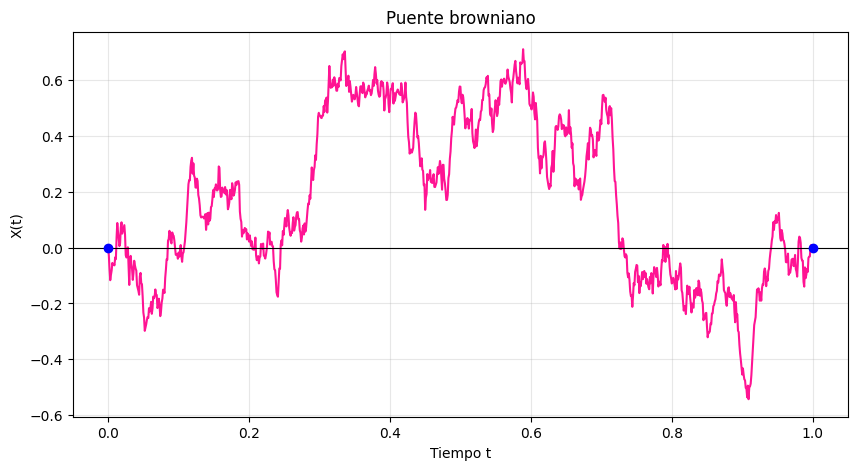

X(0) = 0.0
X(1) = 0.0


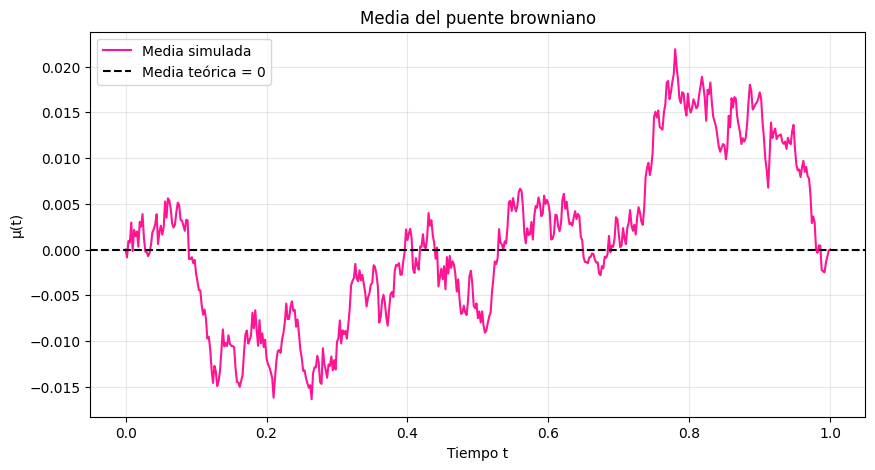

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import random as r


def brown(T, N):
    dt = T / N
    B = [0.0]

    for i in range(N):
        dB = np.sqrt(dt) * np.random.normal(0, 1)
        B.append(B[-1] + dB)

    return np.linspace(0, T, N + 1), np.array(B)

def puente_browniano(T, N):
    t, B = brown(T, N)

    # X_t = B_t - t B_1, para T = 1
    X = B - (t / T) * B[-1]

    return t, X

T = 1
N = 1000

t, X = puente_browniano(T, N)

plt.figure(figsize=(10, 5))
plt.plot(t, X, color="deeppink", linewidth=1.5)
plt.axhline(0, color="black", linewidth=0.8)
plt.scatter([0, 1], [X[0], X[-1]], color="blue", zorder=3)

plt.title("Puente browniano")
plt.xlabel("Tiempo t")
plt.ylabel("X(t)")
plt.grid(alpha=0.3)
plt.show()

print("X(0) =", X[0])
print("X(1) =", X[-1])

T = 1
N = 500
M = 1000

trayectorias = []

for i in range(M):
    t, X = puente_browniano(T, N)
    trayectorias.append(X)

trayectorias = np.array(trayectorias)

# Media empírica en cada instante
mu = np.mean(trayectorias, axis=0)

plt.figure(figsize=(10, 5))
plt.plot(t, mu, color="deeppink", label="Media simulada")
plt.axhline(0, color="black", linestyle="--", label="Media teórica = 0")

plt.title("Media del puente browniano")
plt.xlabel("Tiempo t")
plt.ylabel("μ(t)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

